In [30]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df=pd.read_csv('height-weight.csv',index_col=0)
df.sample(10)

,Height,Weight
Index,,
3620,64.50981,126.8512
20374,68.52782,145.3248
14471,66.08270,116.0096
1518,70.65043,152.9084
14261,66.07261,114.2463
18353,69.34050,129.3896
7338,70.73417,133.0843
20399,67.85106,131.9627
22481,63.28424,102.8488


In [3]:
df.shape

(25000, 2)

Text(0.5, 1.0, 'Height vs Weight')

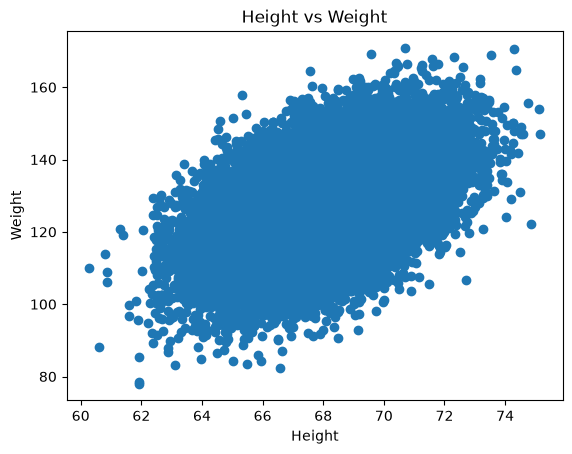

In [5]:
plt.scatter(data=df, x='Height', y='Weight')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.title('Height vs Weight')

In [6]:
X=df[['Height']]
y=df[['Weight']]

In [7]:
X,y

(         Height
 Index          
 1      65.78331
 2      71.51521
 3      69.39874
 4      68.21660
 5      67.78781
 ...         ...
 24996  69.50215
 24997  64.54826
 24998  64.69855
 24999  67.52918
 25000  68.87761
 
 [25000 rows x 1 columns],
          Weight
 Index          
 1      112.9925
 2      136.4873
 3      153.0269
 4      142.3354
 5      144.2971
 ...         ...
 24996  118.0312
 24997  120.1932
 24998  118.2655
 24999  132.2682
 25000  124.8742
 
 [25000 rows x 1 columns])

In [9]:
X_train,X_test,y_train,y_test=train_test_split(X,y, test_size=0.20, random_state=41)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 1 to 25000
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Height  25000 non-null  float64
 1   Weight  25000 non-null  float64
dtypes: float64(2)
memory usage: 390.8 KB


In [12]:
df.describe()

,Height,Weight
count,25000.000000,25000.000000
mean,67.993114,127.079421
std,1.901679,11.660898
min,60.278360,78.014760
25%,66.704397,119.308675
50%,67.995700,127.157750
75%,69.272958,134.892850
max,75.152800,170.924000


In [14]:
scaler=StandardScaler()

In [15]:
np.mean(X_train),np.std(X_train), np.mean(X_test),np.std(X_test)

(np.float64(67.990224029),
 np.float64(1.9078097964358967),
 np.float64(68.00467186799999),
 np.float64(1.876717239834523))

In [16]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [17]:
np.mean(X_train),np.std(X_train), np.mean(X_test),np.std(X_test)

(np.float64(-1.9610979506978767e-15),
 np.float64(1.0),
 np.float64(0.007572997594931781),
 np.float64(0.9837024861391006))

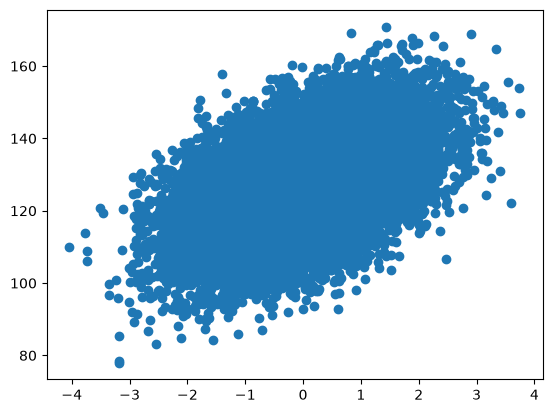

In [18]:
plt.scatter(X_train,y_train)

In [20]:
model=LinearRegression()
model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [21]:
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[5.84]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[127.09]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[141.42]


In [22]:
print(model.coef_)
print(model.intercept_)

[[5.84246577]]
[127.09173588]


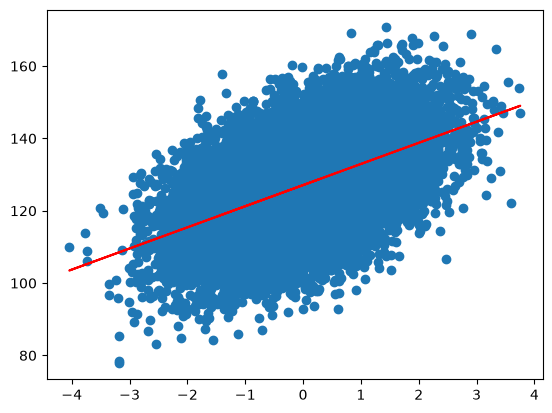

In [23]:
plt.scatter(X_train,y_train)
plt.plot(X_train,model.predict(X_train),'r')

In [24]:
y_predict_test=model.predict(X_test)

In [25]:
y_predict_test,y_test

(array([[126.94298305],
        [133.41908944],
        [121.17183982],
        ...,
        [124.78071833],
        [134.87908591],
        [122.50330759]], shape=(5000, 1)),
          Weight
 Index          
 17414  150.0432
 18579  143.8614
 9110   113.8325
 3275   122.1147
 7966   135.7570
 ...         ...
 21238  122.6718
 7092   137.8864
 24860  122.2566
 7580   125.3443
 13480  129.8035
 
 [5000 rows x 1 columns])

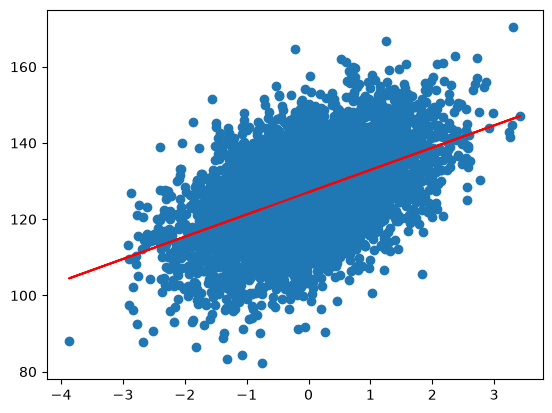

In [26]:
plt.scatter(X_test,y_test)
plt.plot(X_test,model.predict(X_test),'r')

In [31]:
mse=mean_squared_error(y_test,y_predict_test)
mae=mean_absolute_error(y_test,y_predict_test)
rmse=np.sqrt(mse)
score=r2_score(y_test,y_predict_test)
print(mse,mae,rmse,score*100,'%')

102.22721959646476 8.016687673837078 10.110747726872862 25.70107023914987 %
